# UNSW-NB15: does the log transform help the deep models?


## Settings

In [1]:
import gc
import json
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support, f1_score)

import keras
from keras import layers
from keras.callbacks import EarlyStopping
import tensorflow as tf
print("GPUs visible:", tf.config.list_physical_devices("GPU"))

SEED = 0
DATASET_NAME = "UNSW-NB15"

RUN_CNN = True
RUN_LSTM = True

# 0 = no class weighting (the baseline recipe, so the transform is the only change).
# Above 0 = tempered class weights (1 = "balanced"), for the "log transform + weighting" variant.
ALPHA = 0.0

BATCH_SIZE = 256       # same as the baseline CNN and LSTM notebooks
EPOCHS = 50
PATIENCE = 5

# Update these two paths to where the UNSW-NB15 files are saved.
TRAIN_PATH = "UNSW_NB15_training-set.csv"
TEST_PATH = "UNSW_NB15_testing-set.csv"

WINDOW = 10            # records per window for the LSTM, as in UNSW_LSTM.ipynb

GPUs visible: []


## 1. Load and encode (no scaling yet)

In [2]:
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)

# id is a row number and label is a binary copy of the target, so neither is a feature
X_train_raw = df_train.drop(columns=["id", "label", "attack_cat"])
X_test_raw = df_test.drop(columns=["id", "label", "attack_cat"])

# One-hot encode the three categorical columns, then line the test columns up with train
categorical_cols = ["proto", "service", "state"]
X_train_enc = pd.get_dummies(X_train_raw, columns=categorical_cols, drop_first=True)
X_test_enc = pd.get_dummies(X_test_raw, columns=categorical_cols, drop_first=True)
X_train_enc, X_test_enc = X_train_enc.align(X_test_enc, join="left", axis=1, fill_value=0)

# Target: attack_cat -> integer ids
encoder = LabelEncoder()
y_train = encoder.fit_transform(df_train["attack_cat"])
y_test = encoder.transform(df_test["attack_cat"])
class_names = list(encoder.classes_)
n_classes = len(class_names)

# (the scaling happens in the next step, after the log transform)
X_train = X_train_enc.to_numpy(dtype="float64")
X_test = X_test_enc.to_numpy(dtype="float64")
print("Features:", X_train.shape[1], "| min value in train:", float(X_train.min()))

Features: 191 | min value in train: 0.0


## 2. Signed log transform, then standard scaling

Applied to every row of the training and test sets alike, so it uses nothing from the test set. The scaler is fitted on the (transformed) training set only. All UNSW-NB15 features are non-negative, so the transform is a plain `log(1 + x)` here.

In [3]:
def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))

X_train = signed_log(X_train.astype("float64"))
X_test = signed_log(X_test.astype("float64"))

scaler = StandardScaler()                      # fitted on the (transformed) training set only
X_train = scaler.fit_transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")
print("Largest absolute scaled value in train:", float(np.abs(X_train).max()))
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(dict(zip(class_names, np.bincount(y_train, minlength=n_classes).tolist())))

Largest absolute scaled value in train: 418.7362060546875
Train: (175341, 191) | Test: (82332, 191)
{'Analysis': 2000, 'Backdoor': 1746, 'DoS': 12264, 'Exploits': 33393, 'Fuzzers': 18184, 'Generic': 40000, 'Normal': 56000, 'Reconnaissance': 10491, 'Shellcode': 1133, 'Worms': 130}


In [4]:
def evaluate(model_name, config, y_true, y_pred, class_names):
    """Print the metrics, classification report and confusion matrix; return the numbers."""
    labels = np.arange(len(class_names))
    acc = accuracy_score(y_true, y_pred)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="macro", zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)

    print(f"{model_name} ({DATASET_NAME}, {config})")
    print(f"Accuracy {acc:.4f} | Macro precision {macro_p:.3f} | Macro recall {macro_r:.3f} | "
          f"Macro F1 {macro_f1:.3f} | Weighted F1 {weighted_f1:.3f}\n")
    print(classification_report(y_true, y_pred, labels=labels, target_names=class_names,
                                zero_division=0))

    fig, ax = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=labels),
                           display_labels=class_names).plot(ax=ax, xticks_rotation=45,
                                                           cmap="Blues", colorbar=False)
    ax.set_title(f"{model_name} confusion matrix ({DATASET_NAME}, {config})")
    fig.tight_layout()
    plt.show()

    return {"accuracy": acc, "macro_precision": macro_p, "macro_recall": macro_r,
            "macro_f1": macro_f1, "weighted_f1": weighted_f1,
            "report": classification_report(y_true, y_pred, labels=labels,
                                            target_names=class_names, zero_division=0,
                                            output_dict=True)}

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(history.history["accuracy"], label="train")
    axes[0].plot(history.history["val_accuracy"], label="validation")
    axes[0].set_title(f"{title}: accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(history.history["loss"], label="train")
    axes[1].plot(history.history["val_loss"], label="validation")
    axes[1].set_title(f"{title}: loss"); axes[1].set_xlabel("epoch"); axes[1].legend()
    fig.tight_layout(); plt.show()

## 3. Models

The same sequence builder as the LSTM notebooks. The CNN gets a (features, 1) input; the LSTM gets a window of 10 records, as in the baseline runs. The validation split is the same stratified 10% (seed 0) as in the baselines.

In [5]:
class RowSequence(keras.utils.Sequence):
    """Yields (X, y[, sample_weight]) batches.
    window=None -> X is (batch, features, 1); window=W -> X is (batch, W, features).
    `indices` picks which rows are samples; a window always looks back at the real previous rows
    of X, even when only a subset of rows is used for training."""

    def __init__(self, X, y, indices, window=None, batch_size=256, shuffle=False,
                 weights=None, seed=SEED):
        super().__init__()
        self.X, self.y, self.weights = X, y, weights
        self.indices = np.array(indices)
        self.window, self.batch_size, self.shuffle = window, batch_size, shuffle
        self.rng = np.random.default_rng(seed)
        if shuffle:
            self.rng.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, i):
        idx = self.indices[i * self.batch_size:(i + 1) * self.batch_size]
        if self.window is None:
            xb = self.X[idx][:, :, None]
        else:
            offsets = np.arange(-self.window + 1, 1)
            xb = self.X[np.clip(idx[:, None] + offsets[None, :], 0, None)]
        yb = self.y[idx]
        if self.weights is None:
            return xb, yb
        return xb, yb, self.weights[yb]

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indices)

In [6]:
n_features = X_train.shape[1]


tr_idx, val_idx = train_test_split(np.arange(len(X_train)), test_size=0.1,
                                   stratify=y_train, random_state=SEED)
test_all = np.arange(len(X_test))
results = {}
tag = "" if ALPHA == 0 else f"_alpha{ALPHA}"
OUT_FILE = f"results/{DATASET_NAME}_logtransform{tag}.json"

def class_weights_for(y, alpha):
    """Balanced weights raised to the power alpha, rescaled so the mean sample weight is 1."""
    counts = np.maximum(np.bincount(y, minlength=n_classes), 1)
    w = (len(y) / (n_classes * counts)) ** alpha
    return w / w[y].mean()

def build_cnn():
    return keras.Sequential([
        keras.Input(shape=(n_features, 1)),
        layers.Conv1D(64, kernel_size=3, activation="relu", padding="same"),
        layers.MaxPooling1D(pool_size=2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ])

def build_lstm():
    return keras.Sequential([
        keras.Input(shape=(WINDOW, n_features)),
        layers.LSTM(64),
        layers.Dense(n_classes, activation="softmax"),
    ])

def run(key, model_name, config, build, window):
    keras.utils.set_random_seed(SEED)
    w = None if ALPHA == 0 else class_weights_for(y_train[tr_idx], ALPHA)
    train_seq = RowSequence(X_train, y_train, tr_idx, window, BATCH_SIZE, shuffle=True, weights=w)
    val_seq = RowSequence(X_train, y_train, val_idx, window, 1024, weights=w)
    test_seq = RowSequence(X_test, y_test, test_all, window, 1024)
    model = build()
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    early_stop = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(train_seq, validation_data=val_seq, epochs=EPOCHS,
                        callbacks=[early_stop], verbose=2)
    secs = time.perf_counter() - start
    print(f"Trained in {secs:.1f}s ({len(history.history['loss'])} epochs)")
    plot_history(history, config)
    y_pred = model.predict(test_seq, verbose=0).argmax(axis=1)
    result = evaluate(model_name, config, y_test, y_pred, class_names)
    result["train_seconds"] = secs
    result["epochs"] = len(history.history["loss"])
    result["alpha"] = ALPHA
    results[key] = result
    os.makedirs("results", exist_ok=True)
    json.dump(results, open(OUT_FILE, "w"), indent=1, default=float)
    del model
    keras.backend.clear_session()
    gc.collect()

## 4. CNN on log-transformed data

Epoch 1/50
617/617 - 5s - 9ms/step - accuracy: 0.7695 - loss: 0.6319 - val_accuracy: 0.7856 - val_loss: 0.5573
Epoch 2/50
617/617 - 5s - 8ms/step - accuracy: 0.7907 - loss: 0.5348 - val_accuracy: 0.7985 - val_loss: 0.5253
Epoch 3/50
617/617 - 5s - 7ms/step - accuracy: 0.7987 - loss: 0.5119 - val_accuracy: 0.7980 - val_loss: 0.5122
Epoch 4/50
617/617 - 5s - 7ms/step - accuracy: 0.8016 - loss: 0.4998 - val_accuracy: 0.8076 - val_loss: 0.4975
Epoch 5/50
617/617 - 5s - 7ms/step - accuracy: 0.8047 - loss: 0.4908 - val_accuracy: 0.8074 - val_loss: 0.4913
Epoch 6/50
617/617 - 4s - 7ms/step - accuracy: 0.8064 - loss: 0.4846 - val_accuracy: 0.8106 - val_loss: 0.4823
Epoch 7/50
617/617 - 5s - 7ms/step - accuracy: 0.8084 - loss: 0.4796 - val_accuracy: 0.8133 - val_loss: 0.4790
Epoch 8/50
617/617 - 5s - 7ms/step - accuracy: 0.8098 - loss: 0.4749 - val_accuracy: 0.8141 - val_loss: 0.4740
Epoch 9/50
617/617 - 4s - 7ms/step - accuracy: 0.8105 - loss: 0.4728 - val_accuracy: 0.8136 - val_loss: 0.4742
E

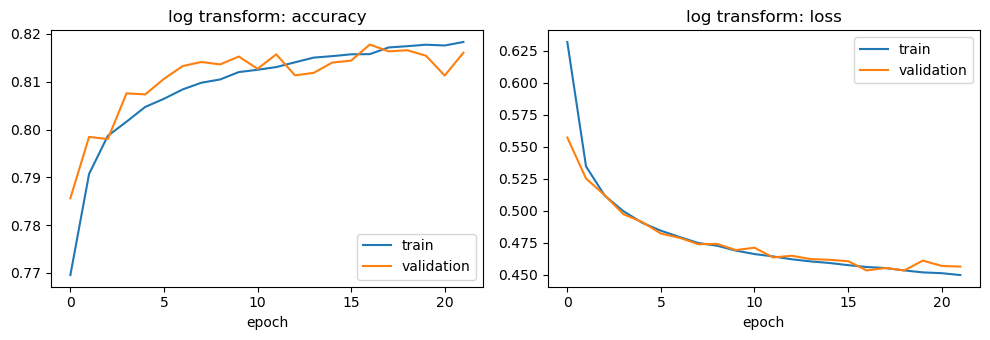

CNN (UNSW-NB15, log transform)
Accuracy 0.7605 | Macro precision 0.488 | Macro recall 0.489 | Macro F1 0.440 | Weighted F1 0.765

                precision    recall  f1-score   support

      Analysis       0.00      0.00      0.00       677
      Backdoor       0.36      0.03      0.06       583
           DoS       0.43      0.06      0.11      4089
      Exploits       0.55      0.92      0.69     11132
       Fuzzers       0.29      0.54      0.38      6062
       Generic       1.00      0.96      0.98     18871
        Normal       0.97      0.74      0.84     37000
Reconnaissance       0.75      0.82      0.78      3496
     Shellcode       0.25      0.65      0.36       378
         Worms       0.29      0.16      0.21        44

      accuracy                           0.76     82332
     macro avg       0.49      0.49      0.44     82332
  weighted avg       0.82      0.76      0.77     82332



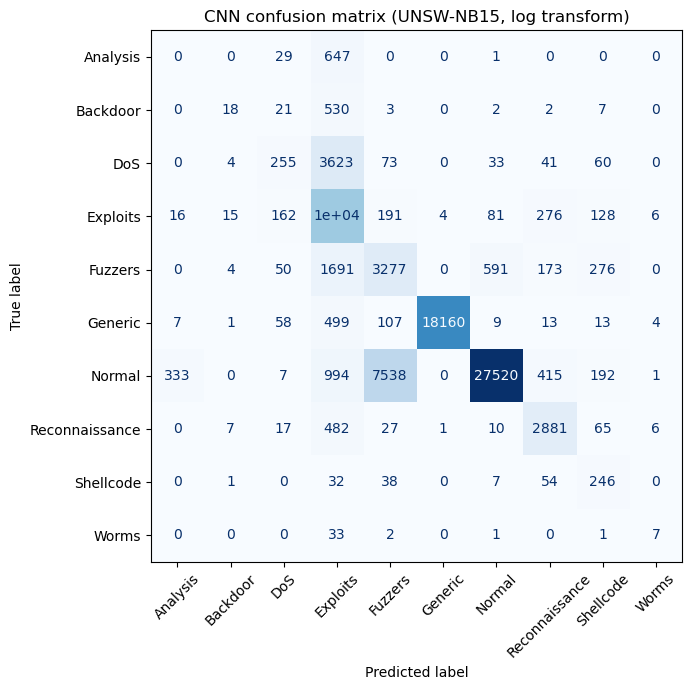

In [7]:
if RUN_CNN:
    run("cnn_log", "CNN", "log transform", build_cnn, window=None)
else:
    print("Skipped")

## 5. LSTM (window 10, 64 units) on log-transformed data

Epoch 1/50
617/617 - 5s - 8ms/step - accuracy: 0.7749 - loss: 0.6544 - val_accuracy: 0.8163 - val_loss: 0.5109
Epoch 2/50
617/617 - 4s - 6ms/step - accuracy: 0.8229 - loss: 0.4843 - val_accuracy: 0.8224 - val_loss: 0.4819
Epoch 3/50
617/617 - 4s - 6ms/step - accuracy: 0.8324 - loss: 0.4546 - val_accuracy: 0.8277 - val_loss: 0.4653
Epoch 4/50
617/617 - 4s - 6ms/step - accuracy: 0.8381 - loss: 0.4347 - val_accuracy: 0.8321 - val_loss: 0.4552
Epoch 5/50
617/617 - 4s - 6ms/step - accuracy: 0.8434 - loss: 0.4193 - val_accuracy: 0.8339 - val_loss: 0.4455
Epoch 6/50
617/617 - 4s - 6ms/step - accuracy: 0.8487 - loss: 0.4061 - val_accuracy: 0.8368 - val_loss: 0.4392
Epoch 7/50
617/617 - 4s - 6ms/step - accuracy: 0.8520 - loss: 0.3943 - val_accuracy: 0.8379 - val_loss: 0.4365
Epoch 8/50
617/617 - 4s - 6ms/step - accuracy: 0.8565 - loss: 0.3844 - val_accuracy: 0.8368 - val_loss: 0.4343
Epoch 9/50
617/617 - 4s - 6ms/step - accuracy: 0.8595 - loss: 0.3752 - val_accuracy: 0.8374 - val_loss: 0.4316
E

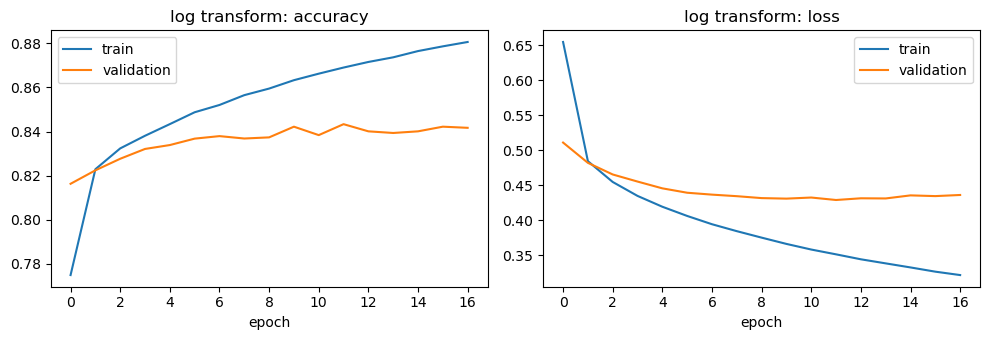

LSTM (window) (UNSW-NB15, log transform)
Accuracy 0.8630 | Macro precision 0.484 | Macro recall 0.478 | Macro F1 0.475 | Weighted F1 0.856

                precision    recall  f1-score   support

      Analysis       0.02      0.00      0.01       677
      Backdoor       0.01      0.00      0.01       583
           DoS       0.32      0.18      0.23      4089
      Exploits       0.59      0.86      0.70     11132
       Fuzzers       0.75      0.65      0.70      6062
       Generic       1.00      0.93      0.96     18871
        Normal       0.99      0.98      0.99     37000
Reconnaissance       0.75      0.79      0.77      3496
     Shellcode       0.40      0.38      0.39       378
         Worms       0.00      0.00      0.00        44

      accuracy                           0.86     82332
     macro avg       0.48      0.48      0.47     82332
  weighted avg       0.86      0.86      0.86     82332



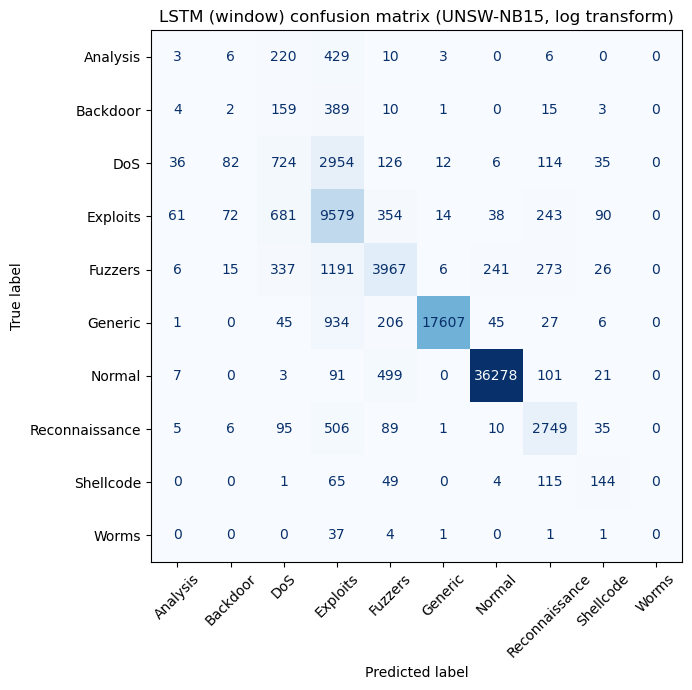

In [8]:
if RUN_LSTM:
    run("lstm_log", "LSTM (window)", "log transform", build_lstm, window=WINDOW)
else:
    print("Skipped")

## 6. Comparison

The new runs next to the existing baselines (standard scaling), the optimised runs and the tree models. Files that are not in `results/` are skipped.

Missing: results/UNSW-NB15_CNN.json
Missing: results/UNSW-NB15_CNN_optimised.json
Missing: results/UNSW-NB15_LSTM_window.json
Missing: results/UNSW-NB15_LSTM_window_optimised.json


,Accuracy,Macro precision,Macro recall,Macro F1,Train time (s)
Decision Tree,0.7282,0.4804,0.5105,0.4796,4.4770
Random Forest,0.7555,0.5264,0.4820,0.4588,3.4521
CNN (log transform),0.7605,0.4884,0.4895,0.4404,99.4802
LSTM (log transform),0.8630,0.4835,0.4781,0.4749,68.0400


,Decision Tree,Random Forest,CNN (log transform),LSTM (log transform)
Analysis,0.034,0.004,0.000,0.008
Backdoor,0.034,0.028,0.057,0.005
DoS,0.230,0.150,0.109,0.228
Exploits,0.642,0.689,0.685,0.702
Fuzzers,0.316,0.403,0.378,0.697
Generic,0.979,0.982,0.981,0.964
Normal,0.834,0.850,0.843,0.986
Reconnaissance,0.845,0.854,0.784,0.770
Shellcode,0.416,0.512,0.360,0.390
Worms,0.465,0.115,0.206,0.000


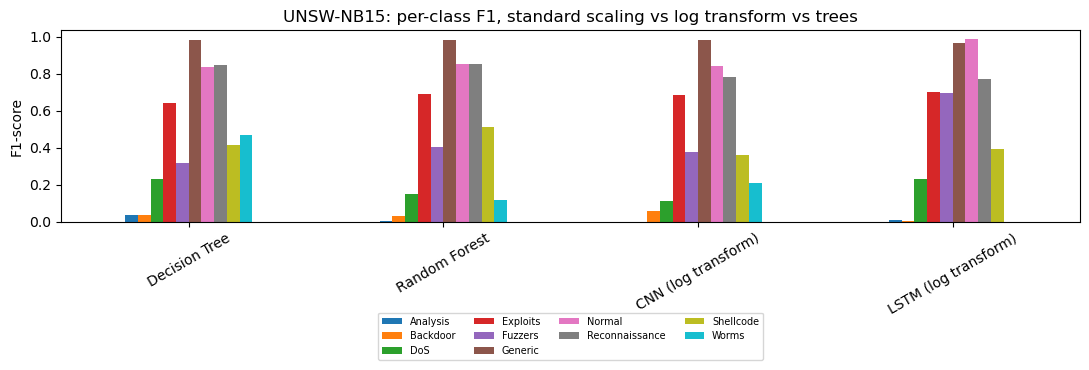

In [10]:
sources = [
    ("Decision Tree", "results/UNSW-NB15_Decision_Tree.json", "baseline"),
    ("Random Forest", "results/UNSW-NB15_Random_Forest.json", "baseline"),
    ("CNN (standard scaling)", "results/UNSW-NB15_CNN.json", "baseline"),
    ("CNN optimised (standard scaling)", "results/UNSW-NB15_CNN_optimised.json", "optimised"),
    ("LSTM window (standard scaling)", "results/UNSW-NB15_LSTM_window.json", "baseline"),
    ("LSTM window optimised (standard scaling)", "results/UNSW-NB15_LSTM_window_optimised.json", "optimised"),
]
allr = {}
for name, path, key in sources:
    if os.path.exists(path):
        allr[name] = json.load(open(path))[key]
    else:
        print("Missing:", path)
suffix = " + weights" if ALPHA > 0 else ""
labels = {"cnn_log": f"CNN (log transform{suffix})", "lstm_log": f"LSTM (log transform{suffix})"}
for k, name in labels.items():
    if k in results:
        allr[name] = results[k]

summary = pd.DataFrame({n: {"Accuracy": r["accuracy"], "Macro precision": r["macro_precision"],
                            "Macro recall": r["macro_recall"], "Macro F1": r["macro_f1"],
                            "Train time (s)": r.get("train_seconds", float("nan"))}
                        for n, r in allr.items()}).T
display(summary.round(4))

per_class = pd.DataFrame({n: [r["report"][c]["f1-score"] for c in class_names] for n, r in allr.items()},
                         index=class_names)
display(per_class.round(3))
ax = per_class.T.plot.bar(figsize=(11, 4.5), rot=30)
ax.set_ylabel("F1-score")
ax.set_title("UNSW-NB15: per-class F1, standard scaling vs log transform vs trees")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=4, fontsize=7)
plt.tight_layout()
plt.show()